# 1. Initial preparation, importing libraries and dataset

In [ ]:
#data handling base
import pandas as pd
import numpy as np

#language identification
from langdetect import detect_langs, DetectorFactory

#feature engineering
import re
import spacy 
from spacy.matcher import Matcher
from collections import Counter
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler


#visualization
import seaborn as sns
import matplotlib.pyplot as plt

c:\Users\Asus Tuf\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [84]:
#import dataset from csv file
df = pd.read_csv('twcs.csv', encoding='utf-8')

In [63]:
#column info
print(df.info())
print(f'\n{'*'* 40}\n')
print('number of NA values:')
print(df.isna().sum())
print(f'\n{'*'* 40}\n')
print('number of duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2811774 entries, 0 to 2811773
Data columns (total 7 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 131.4+ MB
None

****************************************

number of NA values:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64

****************************************

number of duplicate rows: 0


# 2. Data preparation and cleaning

In [85]:
#thread root:
def get_thread_root(tweet_id, parent_map):
    visited = set()
    while tweet_id in parent_map and tweet_id not in visited:
        visited.add(tweet_id)
        tweet_id = parent_map[tweet_id]
    return tweet_id

In [86]:
# pull all tweets belonging to those threads
parent_map = df.dropna(subset=['in_response_to_tweet_id']).set_index('tweet_id')['in_response_to_tweet_id'].to_dict()

df['thread_root'] = df['tweet_id'].apply(lambda x: get_thread_root(x, parent_map))

df['is_root'] = df['in_response_to_tweet_id'].isna()
df['is_end'] = df['response_tweet_id'].isna()
print(df['thread_root'].nunique())

798012


In [7]:
nonthreads = df[df['response_tweet_id'].isna() & df['in_response_to_tweet_id'].isna()]
nonthreads

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end


In [ ]:
# All tweet IDs present in the dataset
parent_ids_in_data = set(df['tweet_id'])

# All parent references (drop NaN roots)
orphaned = df['in_response_to_tweet_id'].dropna()

# Boolean mask: True if parent is missing
mask = ~orphaned.isin(parent_ids_in_data)

orphan_count = mask.sum()
print(f'Orphaned threads: {orphan_count} ({orphan_count/len(df)*100:.1f}%)')

# Create a dataframe of orphaned replies
df_orphans = df.loc[df['in_response_to_tweet_id'].isin(orphaned[mask])]
df_orphans.head()


Orphaned tweets: 3862 (0.1%)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
138,222,115760,True,Tue Oct 31 19:05:30 +0000 2017,@108162 @115761 @ATVIAssist tried that there w...,221,223.000,223.000,False,False
1035,1621,AzureSupport,False,Tue Oct 31 22:11:47 +0000 2017,@116051 Sorry to hear your having trouble. Cou...,1620,1622.000,1622.000,False,False
2817,3745,AmazonHelp,False,Tue Oct 31 22:36:29 +0000 2017,"@116616 David, te recomendamos no compartir in...",3744,3746.000,3746.000,False,False
2848,3777,116625,True,Tue Oct 31 22:53:05 +0000 2017,@AppleSupport I've also forced the app to clos...,3775,3779.000,3779.000,False,False
4082,5530,Ask_Spectrum,False,Tue Oct 31 23:08:39 +0000 2017,@117003 Please remove that from public. I have...,5529,5531.000,5531.000,False,False


In [ ]:
orphan_thr = df_orphans['thread_root']
bfr = len(df)
df = df.loc[~df['thread_root'].isin(orphan_thr)]
aftr = len(df)
print(f'removed {bfr - aftr} tweets')

removed 15909 threads


In [89]:
#find root tweets
twroot = df['thread_root']

#get sample before applying to whole dataset, since 3 mil rows is long to compute.
sampled_roots = twroot.sample(n=20000, random_state=42)
#Instead of sampling dataset directly, I sampled roots, otherwise threads would be truncated

df_sample = df[df['thread_root'].isin(sampled_roots)].copy()
df_sample.head(5)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
81,160,ChipotleTweets,False,Tue Oct 31 22:06:55 +0000 2017,@115737 My apologies for that. Just sent you a...,NaN,161.000,163.000,False,True
82,161,115737,True,Tue Oct 31 21:59:25 +0000 2017,"@ChipotleTweets Tried, didn't work. How rude :/",160,162.000,163.000,False,False
83,162,ChipotleTweets,False,Tue Oct 31 19:51:00 +0000 2017,@115737 Give it a try. -Tara,161,163.000,163.000,False,False
84,163,115737,True,Tue Oct 31 19:43:47 +0000 2017,@ChipotleTweets can I dress up as myself and s...,162,NaN,163.000,True,False
276,383,Morrisons,False,Tue Oct 31 22:05:15 +0000 2017,"@115804 Hi there, sorry about that. Please DM ...",384,385.000,385.000,False,False


In [90]:
df_sample['created_at'] = pd.to_datetime(df_sample['created_at'], format='%a %b %d %H:%M:%S %z %Y', errors='coerce')
df_sample = df_sample.sort_values(['thread_root', 'created_at'])
df_sample['turn_index'] = df_sample.groupby('thread_root').cumcount()
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145117 entries, 84 to 2811652
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   tweet_id                 145117 non-null  int64              
 1   author_id                145117 non-null  object             
 2   inbound                  145117 non-null  bool               
 3   created_at               145117 non-null  datetime64[ns, UTC]
 4   text                     145117 non-null  object             
 5   response_tweet_id        96136 non-null   object             
 6   in_response_to_tweet_id  125640 non-null  float64            
 7   thread_root              145117 non-null  float64            
 8   is_root                  145117 non-null  bool               
 9   is_end                   145117 non-null  bool               
 10  turn_index               145117 non-null  int64              
dtypes: bool(3), date

In [16]:
valid_threads = (
    df_sample.groupby("thread_root")["inbound"]
    .apply(lambda x: x.any() and (~x).any())
)
valid_thread_ids = valid_threads[valid_threads].index

df_sample = df_sample[df_sample["thread_root"].isin(valid_thread_ids)]
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145115 entries, 84 to 2811652
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   tweet_id                 145115 non-null  int64              
 1   author_id                145115 non-null  object             
 2   inbound                  145115 non-null  bool               
 3   created_at               145115 non-null  datetime64[ns, UTC]
 4   text                     145115 non-null  object             
 5   response_tweet_id        96135 non-null   object             
 6   in_response_to_tweet_id  125639 non-null  float64            
 7   thread_root              145115 non-null  float64            
 8   is_root                  145115 non-null  bool               
 9   is_end                   145115 non-null  bool               
 10  turn_index               145115 non-null  int64              
dtypes: bool(3), date

In [91]:
DetectorFactory.seed = 42

def thread_lang_conf(group):
    # detect language on concatenated customer text for the whole thread
    cust_text = " ".join(group[group["inbound"] == True]["text"].astype(str))
    try:
        top = detect_langs(cust_text)[0]
        return pd.Series({"lang": top.lang, "conf": top.prob})
    except:
        return pd.Series({"lang": "unknown", "conf": 0.0})


# detect per thread
lang_conf = df_sample.groupby("thread_root").apply(thread_lang_conf)

# only drop threads confidently detected as non-english
drop_ids = lang_conf[(lang_conf["lang"] != "en") & (lang_conf["conf"] > 0.90)].index

before = df_sample["thread_root"].nunique()
df_sample = df_sample[~df_sample["thread_root"].isin(drop_ids)].copy()
after = df_sample["thread_root"].nunique()

print(f"threads: {before} -> {after} ({before - after} non-english dropped)")

threads: 19477 -> 18626 (851 non-english dropped)


C:\Users\Asus Tuf\AppData\Local\Temp\ipykernel_18764\3337528555.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lang_conf = df_sample.groupby("thread_root").apply(thread_lang_conf)


# 3. Descriptive analysis

In [18]:
# pd.set_option('display.max_colwidth', 100)
# df_sample.style.set_properties(**{'text-align': 'left'})
# print(df_sample["text"].head(30))
# pd.set_option('display.max_colwidth', 30)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### 3.1 Check if sample doesn't differ from dataset


In [19]:
#comparing the percentage of root and end tweets in sample vs full dataset
nullratio = df_sample['in_response_to_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample root tweet percentage = ', nullratio,'%')

nullratio1 = df['in_response_to_tweet_id'].isna().sum() / df.shape[0] * 100
print('root tweet percentage        = ',nullratio1,'%')

nullratio2 = df_sample['response_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample end tweet percentage  = ',nullratio2,'%')

nullratio3 = df['response_tweet_id'].isna().sum() / df.shape[0] * 100
print('end tweet percentage         = ',nullratio3,'%')

sample root tweet percentage =  13.328800944645222 %
root tweet percentage        =  28.411064196590324 %
sample end tweet percentage  =  33.986474397967584 %
end tweet percentage         =  37.04552973766616 %


### 3.2 Author statistics

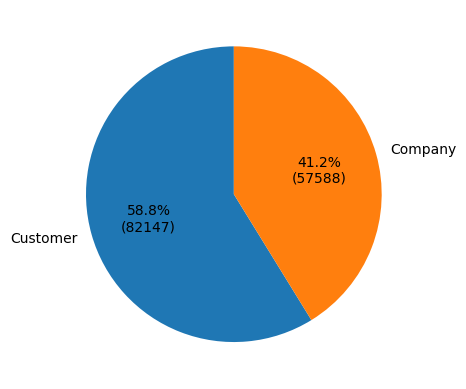

In [20]:
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n({val:d})'
    return my_autopct

inbound = df_sample['inbound'].value_counts()
plt.pie(x=inbound, labels=['Customer', 'Company'], autopct=make_autopct(inbound), startangle = 90)
plt.show()

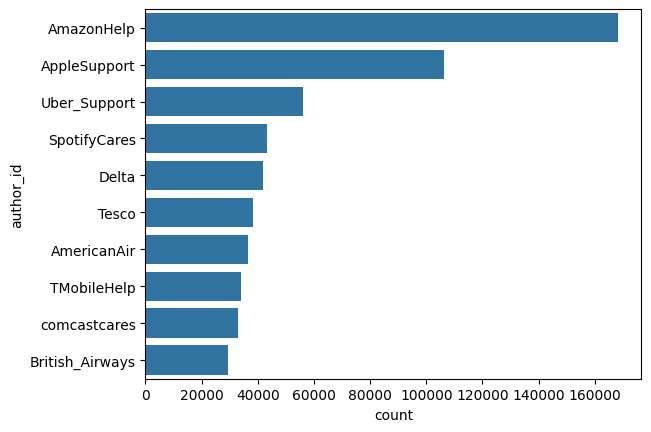

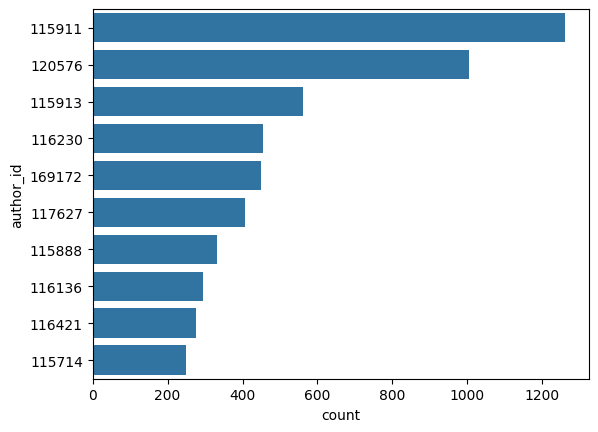

In [21]:
#filter only companies
companies = df[(df['inbound'] == False)]

#top 10 by count
order = companies['author_id'].value_counts().iloc[:10].index

#visualization
sns.countplot(companies['author_id'], order = order)
plt.show()

companies.head(5)

users = df[(df['inbound'] == True)]

order1 = users['author_id'].value_counts().iloc[:10].index

sns.countplot(users['author_id'], order = order1)
plt.show()

In [16]:
author_counts = (
    df.groupby('thread_root')['author_id']
    .nunique()
    .reset_index()
    .rename(columns={'author_id': 'n_distinct_authors'})
)

# Flag multi-party threads
author_counts['multi_party'] = author_counts['n_distinct_authors'] > 2

print(author_counts['n_distinct_authors'].value_counts().sort_index())
print(f"\nMulti-party threads: {author_counts['multi_party'].sum()}")

n_distinct_authors
1          62
2      737641
3       44197
4        6918
5        2088
        ...  
231         1
283         2
337         1
620         1
973         1
Name: count, Length: 120, dtype: int64

Multi-party threads: 56632


### 3.3 Text statistics

<function matplotlib.pyplot.show(close=None, block=None)>

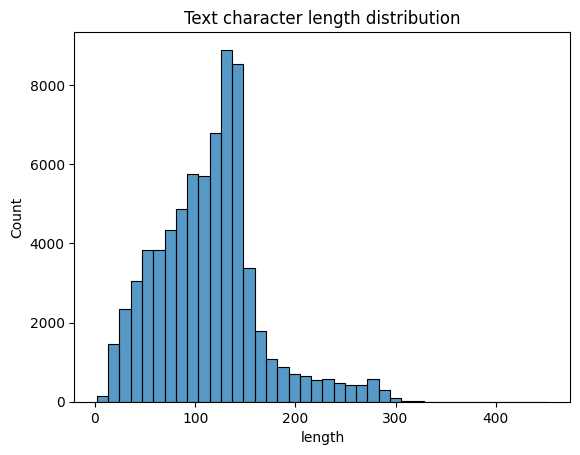

In [17]:
df_sample['chr_length'] = df_sample['text'].str.len()
sns.histplot(df_sample['chr_length'], bins = 40)

plt.title('Text character length distribution')
plt.xlabel('length')
plt.show

### 3.4 Thread statistics

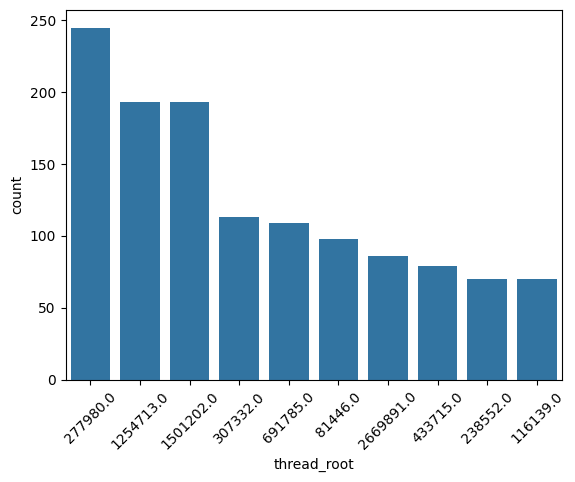

In [18]:
order2 = df_sample['thread_root'].value_counts().iloc[:10].index
sns.countplot(x = 'thread_root', data = df_sample, order = order2)
plt.xticks(rotation=45)
plt.show()

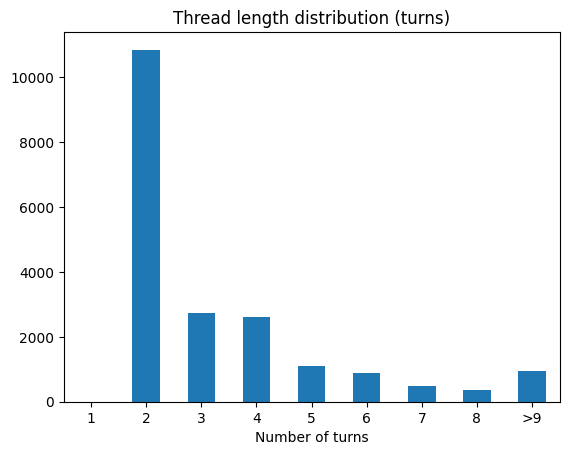

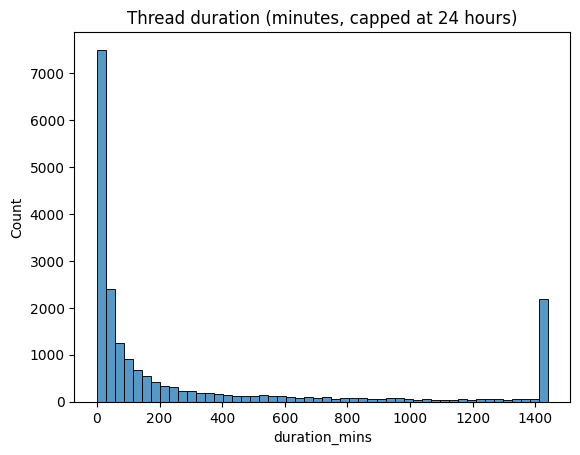

In [19]:
thread_stats = df_sample.groupby('thread_root').agg(
    turn_count=('tweet_id', 'count'),
    duration_mins=('created_at', lambda x: (x.max() - x.min()).total_seconds() / 60)
).reset_index()


bins1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, np.inf]
labels1 = ['1', '2', '3', '4', '5', '6', '7', '8', '>9']
thr = thread_stats['turn_count']


thr_bin = pd.cut(thr, bins=bins1, labels=labels1, right=False)
counts = thr_bin.value_counts().reindex(labels1)
counts.plot(kind='bar')

plt.title('Thread length distribution (turns)')
plt.xlabel('Number of turns')
plt.xticks(rotation = 0)
plt.show()

sns.histplot(thread_stats['duration_mins'].clip(upper=1440), bins=50)
plt.title('Thread duration (minutes, capped at 24 hours)')
plt.show()

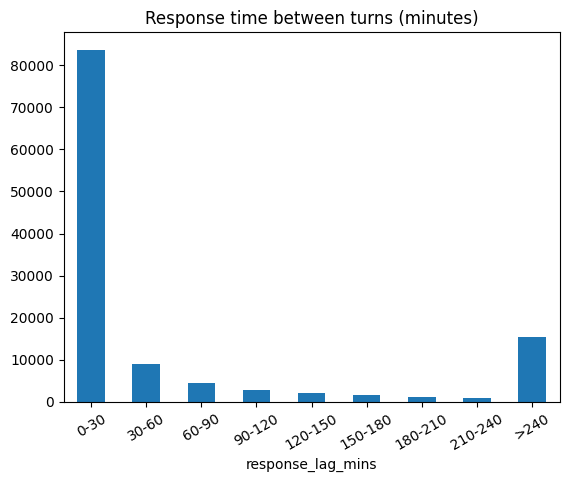

In [22]:
df_sample['response_lag_mins'] = df_sample.groupby('thread_root')['created_at'].diff().dt.total_seconds() / 60
lag = df_sample['response_lag_mins'].dropna()

bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, np.inf]
labels = ['0-30', '30-60', '60-90', '90-120', '120-150', '150-180', '180-210', '210-240', '>240']

lag_binned = pd.cut(lag, bins=bins, labels=labels, right=False)
counts = lag_binned.value_counts().reindex(labels)
counts.plot(kind='bar')
plt.title('Response time between turns (minutes)')
plt.xticks(rotation=30)
plt.show()

In [21]:
thread_stats.describe()


,thread_root,turn_count,duration_mins
count,20000.000,20000.000,20000.000
mean,1571450.710,3.569,1748.607
std,852423.772,4.248,27942.415
min,153.000,2.000,0.183
25%,838651.750,2.000,13.850
50%,1641082.000,2.000,59.850
75%,2291494.000,4.000,358.233
max,2987928.000,245.000,1738020.517


In [22]:
thre = thread_stats[(thread_stats['duration_mins'] > 2880)]
df_sample2 = df_sample[df_sample['thread_root'].isin(thre['thread_root'])]
df_sample2

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins
721,1260,115939,True,2017-10-30 01:02:34+00:00,@hulu_support @115940 my wife and I hate the...,1258,NaN,1260.000,True,False,0,126,NaN
717,1258,hulu_support,False,2017-10-31 22:28:55+00:00,@115939 Oh no! Any aspect about navigation tha...,1259,1260.000,1260.000,False,False,1,131,2726.350
718,1259,115939,True,2017-11-04 12:35:35+00:00,@hulu_support Getting to the lists of episodes...,1261,1258.000,1260.000,False,False,2,148,5166.667
719,1261,hulu_support,False,2017-11-06 23:42:12+00:00,@115939 Apologies for the difficulties! That w...,1262,1259.000,1260.000,False,False,3,136,3546.617
720,1262,115939,True,2017-11-07 00:20:46+00:00,@hulu_support Thanks,NaN,1261.000,1260.000,False,True,4,20,38.567
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2787967,2964467,817920,True,2017-10-19 08:10:46+00:00,@TfL please can you include hand rails for sho...,2964466,NaN,2964467.000,True,False,0,94,NaN
2787966,2964466,817920,True,2017-11-15 22:21:42+00:00,@TfL please can I have a follow up on this tweet?,2964465,2964467.000,2964467.000,False,False,1,49,39730.933
2787965,2964465,TfL,False,2017-11-29 20:37:30+00:00,"@817920 Hi Lucy, sorry for the delay respondin...",NaN,2964466.000,2964467.000,False,True,2,261,20055.800
2791579,2968140,818787,True,2017-11-27 13:18:19+00:00,@AirAsiaSupport hi! Is there an update on flig...,2968139,NaN,2968140.000,True,False,0,137,NaN


In [23]:
thre['duration_mins'].value_counts().sort_index(ascending=False)

duration_mins
1738020.517    1
1508275.800    1
1340663.100    1
1045114.017    1
1044831.183    1
              ..
2884.283       1
2883.683       1
2883.350       1
2882.800       1
2880.750       1
Name: count, Length: 1239, dtype: int64

In [24]:
df_sample2.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,9025.000,7785.000,9025.000,9025.000,9025.000,7785.000
mean,1264680.036,1183248.910,1117767.595,15.137,115.078,3850.371
std,850142.927,835138.368,821594.659,33.064,52.928,42427.830
min,1258.000,1258.000,1260.000,0.000,7.000,0.000
25%,477146.000,418921.000,332671.000,1.000,78.000,4.733
50%,1154175.000,1048312.000,969194.000,4.000,117.000,38.567
75%,1992321.000,1866124.000,1731810.000,11.000,141.000,954.567
max,2984490.000,2978305.000,2968140.000,244.000,452.000,1735649.400


In [25]:
df_sample.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,71386.000,51386.000,71386.000,71386.000,71386.000,51386.000
mean,1511908.284,1473994.360,1486951.485,3.813,113.582,680.577
std,858544.672,861554.008,862261.258,13.005,51.933,16569.955
min,152.000,153.000,153.000,0.000,2.000,0.000
25%,770095.000,734088.250,739402.000,0.000,78.000,3.000
50%,1520886.000,1453887.000,1483440.000,1.000,115.000,12.450
75%,2252562.750,2225360.000,2232701.000,3.000,139.000,78.800
max,2987928.000,2987928.000,2987928.000,244.000,452.000,1735649.400


In [26]:
with pd.option_context("display.max_rows", 1000):
    display(df_sample[df_sample['thread_root'] == 625855])

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins


In [27]:
thread_stats.describe()

,thread_root,turn_count,duration_mins
count,20000.000,20000.000,20000.000
mean,1571450.710,3.569,1748.607
std,852423.772,4.248,27942.415
min,153.000,2.000,0.183
25%,838651.750,2.000,13.850
50%,1641082.000,2.000,59.850
75%,2291494.000,4.000,358.233
max,2987928.000,245.000,1738020.517


In [28]:
(thread_stats['turn_count'] > 4).mean()

np.float64(0.19055)

### 3.5 Temporal statistics

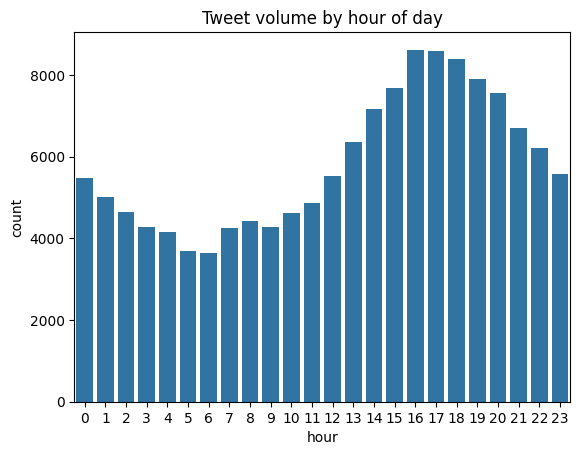

In [23]:
df_sample['hour'] = df_sample['created_at'].dt.hour
sns.countplot(x='hour', data=df_sample)
plt.title('Tweet volume by hour of day')
plt.show()

In [24]:
zero_lag = df_sample[(df_sample['response_lag_mins'] == 0) & (df_sample['inbound'] == True)]
with pd.option_context('display.max_colwidth', 100):
    display (df_sample[(df_sample['thread_root'].isin(zero_lag['thread_root']))].head(30))


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,response_lag_mins,hour
301,409,McDonalds,False,2017-10-31 16:02:50+00:00,So what’ll it be this #Halloween: a trick or a treat? Let us know below. #TrickorTweet https://t...,"410,411,412,413,414,415,416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431,432,433,...",NaN,409.000,True,False,0,NaN,16
2514356,499,754930,True,2017-10-31 16:03:23+00:00,@McDonalds Treat,2684128,409.000,409.000,False,False,1,0.550,16
2514354,500,754929,True,2017-10-31 16:03:43+00:00,@McDonalds I think a treat is in order,2684127,409.000,409.000,False,False,2,0.333,16
1767023,522,571968,True,2017-10-31 16:03:50+00:00,@McDonalds treat! treat! treat!,1921340,409.000,409.000,False,False,3,0.117,16
2514352,501,754928,True,2017-10-31 16:04:08+00:00,@McDonalds Treat! #Trickortweet,2684126,409.000,409.000,False,False,4,0.300,16
2514355,2684128,McDonalds,False,2017-10-31 16:08:38+00:00,@754930 This Coke looks so good you can almost taste it. Almost. #TrickorTweet https://t.co/MY0G...,NaN,499.000,409.000,False,True,5,4.500,16
2514353,2684127,McDonalds,False,2017-10-31 16:13:53+00:00,@754929 Pssstt. Add an apple pie to your next #McFlurry for one frightfully good treat. #Trickor...,NaN,500.000,409.000,False,True,6,5.250,16
2514351,2684126,McDonalds,False,2017-10-31 16:14:02+00:00,@754928 It’s a bird…it’s a plane…it’s a balloon French fry box. #TrickorTweet https://t.co/M44Nn...,NaN,501.000,409.000,False,True,7,0.150,16
2514350,502,754927,True,2017-10-31 16:16:19+00:00,@McDonalds Gimme a trick @McDonalds,2684125,409.000,409.000,False,False,8,2.283,16
1763113,498,570969,True,2017-10-31 16:18:37+00:00,@McDonalds Trick #trickortreat,1916950,409.000,409.000,False,False,9,2.300,16


In [25]:
root_tweets = df_sample[df_sample['tweet_id'] == df_sample['thread_root']]
print(root_tweets['inbound'].value_counts())

inbound
True     18177
False      448
Name: count, dtype: int64


In [26]:
customer_roots = root_tweets[root_tweets['inbound'] == True]['tweet_id']
df_sample = df_sample[df_sample['thread_root'].isin(customer_roots)]

# 4. Linguistic Features

In [27]:
nlp = spacy.load("en_core_web_sm")


INBOUND_INTENT = {
    "cancel", "cancelled", "cancelling", "cancellation",
    "sue", "suing", "lawsuit", "lawyer", "legal",
    "ombudsman", "ofcom", "regulator", "watchdog",
    "chargeback", "refund", "reimbursement",
    "switching", "leaving", "elsewhere",
}

INBOUND_FRUSTRATION = {
    "unacceptable", "ridiculous", "disgusting", "outrageous",
    "appalling", "pathetic", "terrible", "horrible",
    "useless", "incompetent", "shameful", "shocking",
    "furious", "livid", "angry", "disgusted",
    "scam", "fraud", "lied", "liar", "cheated",
}

OUTBOUND_DEFLECTION = {
    "unable", "cannot", "policy", "procedure",
    "terms", "conditions", "unfortunately",
    "different", "department", "another", "team",
    "contact", "reach",
}

OUTBOUND_BUREAUCRATIC = {
    "kindly", "advised", "note", "patience",
    "understand", "appreciate", "bear",
    "investigate", "flag", "raise", "pass",
}

OUTBOUND_FORMAL_VOCAB = {
    "furthermore", "however", "subsequently", "regarding",
    "henceforth", "accordance", "hereby", "therein",
    "aforementioned", "notwithstanding", "whilst",
    "therefore", "thus", "hence", "wherein",
}

CONTRACTIONS = {
    "i'm", "we'll", "can't", "won't", "didn't", "we're",
    "you're", "it's", "that's", "there's", "don't", "isn't",
    "they're", "i'll", "i've", "you've", "we've",
}

INFORMAL_ABBREVIATIONS = {
    "dm", "asap", "fyi", "tbh", "imo",
    "btw", "ngl", "ty", "thx", "pls", "plz",
}

NEGATIVE_EMOJIS = {
    "😡", "😤", "🤬", "😠", "😒", "🙄", "💀", "😑", 
    "😫", "😩", "😣", "🖕", "😖", "😤"
}

NEGATION_TOKENS = {
    "not", "no", "never", "neither", "nor", "n't", "cant",       
    "won't", "wont", "didn't", "didnt", "don't", "dont",
    "isn't", "isnt", "wasn't", "wasnt", "couldn't", "couldnt", "shouldnt", "shouldn't"
}

In [28]:
def build_category_matchers(nlp):
    matchers = {}
    for name, termset in [
        ("inbound_intent",        INBOUND_INTENT),
        ("inbound_frustration",   INBOUND_FRUSTRATION),
        ("outbound_deflection",   OUTBOUND_DEFLECTION),
        ("outbound_bureaucratic", OUTBOUND_BUREAUCRATIC),
        ("outbound_formal_vocab", OUTBOUND_FORMAL_VOCAB),
    ]:
        m = Matcher(nlp.vocab)
        for term in termset:
            pattern = [{"LOWER": w} for w in term.split()]
            m.add(term, [pattern])
        matchers[name] = m
    return matchers

category_matchers = build_category_matchers(nlp)

In [29]:
def formality_score(doc) -> float:
    tokens = [t for t in doc if not t.is_space and not t.is_punct]
    if not tokens:
        return 50.0

    total = len(tokens)
    pos_counts = Counter(t.pos_ for t in tokens)

    noun = pos_counts.get("NOUN", 0) + pos_counts.get("PROPN", 0)
    adj  = pos_counts.get("ADJ", 0)
    prep = pos_counts.get("ADP", 0) 
    art  = pos_counts.get("DET", 0)  
    pron = pos_counts.get("PRON", 0)
    verb = pos_counts.get("VERB", 0) + pos_counts.get("AUX", 0)
    adv  = pos_counts.get("ADV", 0)
    intj = pos_counts.get("INTJ", 0)

    f = ((noun + adj + prep + art - pron - verb - adv - intj)
         / total * 100 + 100) / 2

    return round(f, 4)


In [30]:
def informal_markers(doc, text: str) -> dict:
    tokens_lower = [t.lower_ for t in doc if not t.is_space]

    return {
        "contraction_count":  sum(1 for t in tokens_lower if t in CONTRACTIONS),
        "abbreviation_count": sum(1 for t in tokens_lower if t in INFORMAL_ABBREVIATIONS),
        "has_exclamation":    int("!" in text),
        "has_ellipsis":       int("..." in text),
    }

In [31]:
def extract_spacy_features(text: str, is_inbound: bool, doc=None) -> dict:
    if doc is None:
        doc = nlp(text)

    tokens       = [t for t in doc if not t.is_space]
    alpha_tokens = [t for t in tokens if t.is_alpha]

    token_count  = len(tokens)
    punct_count  = sum(1 for t in tokens if t.is_punct)
    upper_count  = sum(1 for t in alpha_tokens if t.text.isupper())
    caps_ratio   = upper_count / len(alpha_tokens) if alpha_tokens else 0.0

    # Negation 
    has_negation = int(any(t.lower_ in NEGATION_TOKENS for t in tokens))

    # POS counts 
    pos_counts = Counter(t.pos_ for t in tokens)
    verb_count = pos_counts.get("VERB", 0)
    adj_count  = pos_counts.get("ADJ", 0)
    noun_count = pos_counts.get("NOUN", 0)

    # NER 
    ner_counts  = Counter(ent.label_ for ent in doc.ents)
    has_money   = int(ner_counts.get("MONEY", 0) > 0)
    has_org     = int(ner_counts.get("ORG", 0) > 0)

    # Direction-exclusive features 
    if is_inbound:

        # category flags
        has_intent      = int(len(category_matchers["inbound_intent"](doc)) > 0)
        has_frustration = int(len(category_matchers["inbound_frustration"](doc)) > 0)
        has_deflection  = 0
        has_bureaucratic= 0

        # negative emoji
        has_negative_emoji = int(any(ch in NEGATIVE_EMOJIS for ch in text))

        # formality
        f_score             = None
        has_formal_vocab    = 0
        contraction_count   = 0
        abbreviation_count  = 0
        has_passive         = 0
        uses_we_not_i       = 0

    else:

        # Category flags
        has_intent      = 0
        has_frustration = 0
        has_deflection  = int(len(category_matchers["outbound_deflection"](doc)) > 0)
        has_bureaucratic= int(len(category_matchers["outbound_bureaucratic"](doc)) > 0)

        # Negative emoji
        has_negative_emoji = 0

        # Formality score (continuous)
        f_score = formality_score(doc)

        # Formal vocabulary flag
        has_formal_vocab = int(
            len(category_matchers["outbound_formal_vocab"](doc)) > 0
        )

        # Informal markers
        tokens_lower       = [t.lower_ for t in tokens]
        contraction_count  = sum(1 for t in tokens_lower if t in CONTRACTIONS)
        abbreviation_count = sum(1 for t in tokens_lower if t in INFORMAL_ABBREVIATIONS)

        # Passive voice
        has_passive = int(any(t.dep_ == "auxpass" for t in doc))

        pronoun_tokens = [t for t in doc
                          if t.pos_ == "PRON" and t.lower_ in {"i", "we"}]
        uses_we_not_i  = int(
            len(pronoun_tokens) > 0 and
            all(t.lower_ == "we" for t in pronoun_tokens)
        )

    return {
        # Surface
        "token_count":          token_count,
        "punct_count":          punct_count,
        "caps_ratio":           round(caps_ratio, 4),
        # Linguistic
        "has_negation":         has_negation,
        "verb_count":           verb_count,
        "adj_count":            adj_count,
        "noun_count":           noun_count,
        # NER
        "has_money_entity":     has_money,
        "has_org_entity":       has_org,
        # Inbound-exclusive
        "has_intent_term":      has_intent,
        "has_frustration_term": has_frustration,
        "has_negative_emoji":   has_negative_emoji,
        # Outbound-exclusive
        "has_deflection_term":   has_deflection,
        "has_bureaucratic_term": has_bureaucratic,
        "formality_score":       f_score,
        "has_formal_vocab":      has_formal_vocab,
        "contraction_count":     contraction_count,
        "abbreviation_count":    abbreviation_count,
        "has_passive":           has_passive,
        "uses_we_not_i":         uses_we_not_i,
    }

In [32]:
def extract_features_batch(df: pd.DataFrame,
                            text_col: str = "text",
                            inbound_col: str = "inbound",
                            batch_size: int = 256,
                            n_process: int = 1) -> pd.DataFrame:

    texts    = df[text_col].fillna("").tolist()
    inbounds = df[inbound_col].tolist()
    records  = []

    docs = nlp.pipe(texts, batch_size=batch_size, n_process=n_process)

    for doc, is_inbound in zip(docs, inbounds):
        records.append(
            extract_spacy_features(doc.text, is_inbound=bool(is_inbound), doc=doc)
        )

    features_df = pd.DataFrame(records, index=df.index)
    return pd.concat([df, features_df], axis=1)

In [33]:
print(f'spaCy extraction on {len(df_sample)} tweets')
df_ft1 = extract_features_batch(df_sample, text_col="text")

spaCy extraction on 116337 tweets


In [34]:
df_ft1

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,...,has_frustration_term,has_negative_emoji,has_deflection_term,has_bureaucratic_term,formality_score,has_formal_vocab,contraction_count,abbreviation_count,has_passive,uses_we_not_i
84,163,115737,True,2017-10-31 19:43:47+00:00,@ChipotleTweets can I dress up as myself and s...,162,NaN,163.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
83,162,ChipotleTweets,False,2017-10-31 19:51:00+00:00,@115737 Give it a try. -Tara,161,163.000,163.000,False,False,...,0,0,0,0,50.000,0,0,0,0,0
82,161,115737,True,2017-10-31 21:59:25+00:00,"@ChipotleTweets Tried, didn't work. How rude :/",160,162.000,163.000,False,False,...,0,0,0,0,NaN,0,0,0,0,0
81,160,ChipotleTweets,False,2017-10-31 22:06:55+00:00,@115737 My apologies for that. Just sent you a...,NaN,161.000,163.000,False,True,...,0,0,0,0,46.154,0,0,1,0,0
280,385,115804,True,2017-10-31 21:28:45+00:00,@Morrisons so fed up of this very familiar sig...,383,NaN,385.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2811158,2987344,UPSHelp,False,2017-11-21 23:14:00+00:00,@823695 -I apologize that your package was del...,NaN,2987345.000,2987345.000,False,True,...,0,0,0,0,55.000,0,0,1,1,1
2811354,2987541,823751,True,2017-10-31 21:47:06+00:00,So mad @115817 can't manage to deliver package...,2987540,NaN,2987541.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0
2811353,2987540,UPSHelp,False,2017-10-31 21:49:00+00:00,@823751 Please send us a DM with the tracking ...,NaN,2987541.000,2987541.000,False,True,...,0,0,1,0,60.000,0,0,1,0,1
2811653,2987832,823835,True,2017-11-30 07:45:34+00:00,@Safaricom_Care i have rcvd the two msgs and i...,2987831,NaN,2987832.000,True,False,...,0,0,0,0,NaN,0,0,0,0,0


In [35]:
cols = ['has_intent_term', 'has_frustration_term', 'has_deflection_term', 'has_bureaucratic_term', 'has_negative_emoji', 'has_money_entity', 'has_org_entity']
df_ft1[cols].apply(pd.Series.value_counts)

,has_intent_term,has_frustration_term,has_deflection_term,has_bureaucratic_term,has_negative_emoji,has_money_entity,has_org_entity
0,113847,114244,109160,111557,115227,113521,75718
1,2490,2093,7177,4780,1110,2816,40619


In [36]:
df_ft1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 116337 entries, 84 to 2811652
Data columns (total 33 columns):
 #   Column                   Non-Null Count   Dtype              
---  ------                   --------------   -----              
 0   tweet_id                 116337 non-null  int64              
 1   author_id                116337 non-null  object             
 2   inbound                  116337 non-null  bool               
 3   created_at               116337 non-null  datetime64[ns, UTC]
 4   text                     116337 non-null  object             
 5   response_tweet_id        78362 non-null   object             
 6   in_response_to_tweet_id  98160 non-null   float64            
 7   thread_root              116337 non-null  float64            
 8   is_root                  116337 non-null  bool               
 9   is_end                   116337 non-null  bool               
 10  turn_index               116337 non-null  int64              
 11  response_lag_min

In [37]:
df_ft1[df_ft1['has_negative_emoji'] == 1]

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,...,has_frustration_term,has_negative_emoji,has_deflection_term,has_bureaucratic_term,formality_score,has_formal_vocab,contraction_count,abbreviation_count,has_passive,uses_we_not_i
1274209,1404868,446616,True,2017-10-28 18:18:53+00:00,@122739 @115911 Same 😩 idk what to expect,1404867,1404869.000,1072.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
1779251,1109,575184,True,2017-10-28 20:26:58+00:00,@115911 I've been with you since early days of...,1932903,1072.000,1072.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
1725211,1121,398362,True,2017-10-29 01:24:52+00:00,"@115911 I’m just trying to pay my phone bill, ...",1879269,1072.000,1072.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
1823386,1153,585929,True,2017-10-31 19:57:13+00:00,@115911 I was told I was not eligible to upgra...,1979030,1072.000,1072.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
1306471,1107,454159,True,2017-11-02 11:27:43+00:00,@115911 I just upgraded to the 7+ on Mother’s ...,1439949,1072.000,1072.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2798375,2974935,740449,True,2017-10-31 18:57:38+00:00,@AskeBay Sort your site out please. I can't co...,"2974934,2974936",NaN,2974935.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0
2798709,2975265,820557,True,2017-11-30 02:44:27+00:00,@820556 @AmericanAir @114180 @Delta It not lik...,"2975266,2975267",2975263.000,2975287.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
2798713,2975270,820557,True,2017-11-30 04:33:00+00:00,@286923 @820556 @AmericanAir @114180 @Delta We...,2975272,2975269.000,2975287.000,False,False,...,0,1,0,0,NaN,0,0,0,0,0
2803006,2979405,821700,True,2017-11-30 01:12:27+00:00,"I got in an accident Monday, had some shitty s...",2979404,NaN,2979405.000,True,False,...,0,1,0,0,NaN,0,0,0,0,0


# 5. Sentiment Features

In [38]:
def preprocess(text):
    text = re.sub(r"http\S+", "http", text)
    text = re.sub(r"@\w+", "@user", text)
    return text.strip()

In [39]:
def score_batch(texts, batch_size=32):
    results = []

    for i in range(0, len(texts), batch_size):
        batch = [preprocess(t) for t in texts[i : i + batch_size]]

        inputs = tokenizer(
            batch,
            return_tensors="pt",
            truncation=True,
            max_length=128,
            padding=True 
        ).to(device)

        with torch.no_grad():
            logits = model(**inputs).logits

        probs = F.softmax(logits, dim=1).cpu().numpy()

        for row in probs:
            results.append({
                "sentiment_neg": round(float(row[0]), 4),
                "sentiment_neu": round(float(row[1]), 4),
                "sentiment_pos": round(float(row[2]), 4),
            })

        if i % 5000 == 0:
            print(f"  done {i}/{len(texts)}")

    return results

In [40]:
def score_tweets_batch(texts: list,
                        batch_size: int = 32,
                        max_length: int = 128) -> list:
    """
    Score a list of tweet strings.
    Returns a list of dicts with sentiment_neg, sentiment_neu, sentiment_pos.
    """
    results = []

    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]

        #preprocess each tweet in the batch
        batch_processed = [preprocess_for_roberta(t) for t in batch]

        inputs = tokenizer(
            batch_processed,
            return_tensors="pt",
            truncation=True,
            max_length=max_length,
            padding=True,
        ).to(device)

        with torch.no_grad():
            logits = model(**inputs).logits

        #convert raw logits to probabilities
        probs = F.softmax(logits, dim=1).cpu().numpy()

        for row in probs:
            results.append({
                "sentiment_neg": round(float(row[0]), 4),
                "sentiment_neu": round(float(row[1]), 4),
                "sentiment_pos": round(float(row[2]), 4),
            })

        if (i // batch_size) % 50 == 0:
            print(f"  Scored {min(i + batch_size, len(texts))}/{len(texts)} tweets...")

    return results

In [41]:
MODEL = "cardiffnlp/twitter-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model     = AutoModelForSequenceClassification.from_pretrained(MODEL)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = model.to(device)
model.eval()
print(f"running on: {device}")

# run on full dataset
texts  = df_ft1["text"].fillna("").tolist()
scores = score_batch(texts, batch_size=32)

scores_df      = pd.DataFrame(scores, index=df_ft1.index)
tweets_scored  = pd.concat([df_ft1, scores_df], axis=1)

print(tweets_scored.groupby("inbound")[["sentiment_neg", "sentiment_neu", "sentiment_pos"]].mean().round(3))

tweets_scored.to_csv("tweets_sentiment.csv", index=False)
print("saved -> tweets_sentiment.csv")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 20081.83it/s]


running on: cpu
  done 0/116337


KeyboardInterrupt: 

In [ ]:
out = tweets_scored[tweets_scored["inbound"] == False].copy()

print("--- high negative outbound ---")
print(out.nlargest(10, "sentiment_neg")[["text", "sentiment_neg"]].to_string())

print("\n--- outbound neg distribution ---")
print(out["sentiment_neg"].describe().round(3))
print("\noutbound tweets with neg > 0.5:", (out["sentiment_neg"] > 0.5).sum())
print("outbound tweets with neg > 0.3:", (out["sentiment_neg"] > 0.3).sum())

--- high negative outbound ---
                                                                                                                                                                                                                                                                             text  sentiment_neg
1236533                                                                                                                                                                                                 @272953 Hi, thanks for contacting us.  This doesn't sound good! :-(  *HML          0.963
179897                                                                                                                                                                            @166620 This doesn't sound good at all! How long have you been experiencing service issues? -JC          0.961
1616929                                                                                               

In [ ]:
inb = tweets_scored[tweets_scored["inbound"] == True].copy()

print("--- high negative inb ---")
print(inb.nlargest(10, "sentiment_neg")[["text", "sentiment_neg"]].to_string())
print("\n--- inb neg distribution ---")
print(inb["sentiment_neg"].describe().round(3))

print("\ninb tweets with neg > 0.5:", (inb["sentiment_neg"] > 0.5).sum())
print("inb tweets with neg > 0.3:", (inb["sentiment_neg"] > 0.3).sum())

--- high negative inb ---
                                                                                                                                                                                                                                       text  sentiment_neg
462830                                                                                                                              i am so tired being on the phone with @AmazonHelp customer care!!!!y'all useless and not helpful at all          0.985
457261    I fucking hate @115873 every single time I use It (which is almost every day) there is an issue either with the app glitching, the driver being crazy or unauthorized charges on my account. Customer service is BEYOND pathetic.          0.985
1545097                                                                                                                             I'm so disappointed in the horrible customer service I receieved at 2 @115911 stores this

In [ ]:
# tweets_scored = pd.read_csv('tweets_sentiment.csv', encoding='utf-8')

In [44]:
tweets_scored["formality_score"] = tweets_scored["formality_score"].fillna(0.0)

# 6. Thread-level Feature Aggregation

In [45]:
def get_slope(neg, turns):
    # slope of customer negative sentiment over the convo
    if len(neg) < 2:
        return 0.0
    return round(float(np.polyfit(turns, neg, 1)[0]), 4)

In [46]:
def get_agent_sim(texts):
    # how similar are the agent replies to each other
    if len(texts) < 2:
        return 0.0
    try:
        tf  = TfidfVectorizer().fit_transform(texts)
        sim = cosine_similarity(tf)
        n   = sim.shape[0]
        vals = [sim[i][j] for i in range(n) for j in range(i+1, n)]
        return round(sum(vals) / len(vals), 4)
    except:
        return 0.0

In [47]:
rows = []

for tid, g in tweets_scored.groupby("thread_root"):
    inb = g[g["inbound"] == True].sort_values("turn_index")
    out = g[g["inbound"] == False].sort_values("turn_index")

    d = {}
    d["thread_root"] = tid
    d["turn_count"]  = len(g)
    d["inb_turns"]   = len(inb)
    d["out_turns"]   = len(out)

    # customer sentiment
    d["neg_ratio"]               = round(float((inb["sentiment_neg"] > 0.5).mean()), 4)
    d["inb_neg_mean"]            = round(float(inb["sentiment_neg"].mean()), 4)
    d["inb_neg_median"]          = round(float(inb["sentiment_neg"].median()), 4)
    d["inb_neg_max"]             = round(float(inb["sentiment_neg"].max()), 4)
    d["sentiment_trajectory"]    = get_slope(inb["sentiment_neg"].tolist(), inb["turn_index"].tolist())
    # company sentiment - mean and median bc mean gets pulled by outliers
    d["out_neg_mean"]            = round(float(out["sentiment_neg"].mean()), 4)
    d["out_neg_median"]          = round(float(out["sentiment_neg"].median()), 4)


    # customer escalation flags
    d["inb_intent_any"]          = int(inb["has_intent_term"].any())
    d["inb_frustration_any"]     = int(inb["has_frustration_term"].any())
    d["inb_neg_emoji_any"]       = int(inb["has_negative_emoji"].any())
    d["inb_negation_ratio"]      = round(float(inb["has_negation"].mean()), 4)
    d["inb_caps_mean"]           = round(float(inb["caps_ratio"].mean()), 4)
    d["inb_money_any"]           = int(inb["has_money_entity"].any())

    # company escalation flags
    d["out_deflection_any"]      = int(out["has_deflection_term"].any())
    d["out_bureaucratic_any"]    = int(out["has_bureaucratic_term"].any())
    d["out_abbrev_mean"]         = round(float(out["abbreviation_count"].mean()), 4)
    d["out_neu_mean"] = round(float(out["sentiment_neu"].mean()), 4)

    # company formality
    d["out_formality_mean"]      = round(float(out["formality_score"].mean()), 4)
    d["out_formal_vocab_any"]    = int(out["has_formal_vocab"].any())
    d["out_passive_ratio"]       = round(float(out["has_passive"].mean()), 4)
    d["out_contraction_mean"]    = round(float(out["contraction_count"].mean()), 4)
    d["out_we_ratio"]            = round(float(out["uses_we_not_i"].mean()), 4)

    # templated response detection
    d["agent_sim"] = get_agent_sim(out["text"].fillna("").tolist())

    # response time
    d["response_lag_mean"] = round(float(g["response_lag_mins"].mean()), 4)
    d["response_lag_max"]  = round(float(g["response_lag_mins"].max()), 4)

    root_hour = g.sort_values("turn_index").iloc[0]["hour"]
    d["root_hour"] = int(root_hour)
    
    rows.append(d)

df_threads = pd.DataFrame(rows)

print(f"tweets {len(tweets_scored)} -> threads {len(df_threads)}")
print(df_threads.describe().round(3))

df_threads.to_csv("threads_aggregated.csv", index=False)
print("saved")

tweets 69135 -> threads 19828
       thread_root  turn_count  inb_turns  out_turns  neg_ratio  inb_neg_mean  \
count    19828.000   19828.000  19828.000  19828.000  19828.000     19828.000   
mean   1571665.752       3.487      1.915      1.572      0.510         0.479   
std     852230.661       3.408      2.164      1.422      0.442         0.326   
min        153.000       2.000      1.000      1.000      0.000         0.001   
25%     838651.750       2.000      1.000      1.000      0.000         0.171   
50%    1641922.000       2.000      1.000      1.000      0.500         0.480   
75%    2290766.750       4.000      2.000      2.000      1.000         0.783   
max    2987928.000     245.000    149.000     96.000      1.000         0.985   

       inb_neg_median  inb_neg_max  sentiment_trajectory  out_neg_mean  ...  \
count       19828.000    19828.000             19828.000     19828.000  ...   
mean            0.477        0.579                -0.033         0.134  ...   
std

<Axes: xlabel='turn_count'>

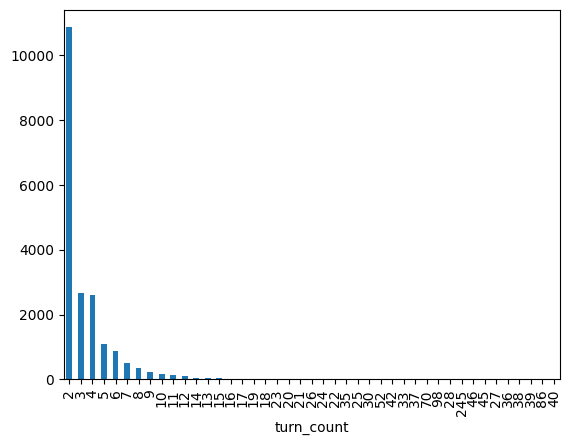

In [48]:
df_threads['turn_count'].value_counts().plot(kind='bar')

In [49]:
print(df_threads["turn_count"].quantile([0.5, 0.75, 0.9, 0.95]))

0.500   2.000
0.750   4.000
0.900   6.000
0.950   8.000
Name: turn_count, dtype: float64


In [50]:
last_inb = (
    tweets_scored[tweets_scored["inbound"] == True]
    .sort_values("turn_index")
    .groupby("thread_root")
    .tail(1)
    .set_index("thread_root")["sentiment_neg"]
)
df_threads["last_inb_neg"] = df_threads["thread_root"].map(last_inb)

# 7. Proxy label

In [52]:

q75 = df_threads["turn_count"].quantile(0.75)
# q90 = df_threads["turn_count"].quantile(0.90)
# print(f"75th pct turn_count: {q75},  90th pct: {q90}\n")

# candidates = {
#     "long(q75) AND traj>=0":
#         (df_threads["turn_count"] >= q75) & (df_threads["sentiment_trajectory"] >= 0),

#     "long(q75) AND last_neg>0.5":
#         (df_threads["turn_count"] >= q75) & (df_threads["last_inb_neg"] > 0.5),

#     "long(q75) AND (traj>=0 OR last_neg>0.5)":
#         (df_threads["turn_count"] >= q75) &
#         ((df_threads["sentiment_trajectory"] >= 0) | (df_threads["last_inb_neg"] > 0.5)),

#     "long(q90) AND last_neg>0.5":
#         (df_threads["turn_count"] >= q90) & (df_threads["last_inb_neg"] > 0.5),

#     "long(q75) AND traj>=0 AND last_neg>0.5":
#         (df_threads["turn_count"] >= q75) &
#         (df_threads["sentiment_trajectory"] >= 0) &
#         (df_threads["last_inb_neg"] > 0.5),
# }

# n = len(df_threads)
# for name, mask in candidates.items():
#     count = int(mask.sum())
#     print(f"{count:>6}  ({count/n*100:5.1f}%)   {name}")

In [53]:
df_threads["escalated"] = (
    (df_threads["turn_count"] >= q75) &
    ((df_threads["sentiment_trajectory"] >= 0) | (df_threads["last_inb_neg"] > 0.5))
).astype(int)
    

In [54]:
sample_ids = df_threads[df_threads["escalated"] == 1]["thread_root"].sample(10, random_state=1)
for tid in sample_ids:
    convo = tweets_scored[tweets_scored["thread_root"] == tid].sort_values("turn_index")
    print(f"\n--- thread {tid} (turns={len(convo)}) ---")
    for _, r in convo.iterrows():
        who = "CUST" if r["inbound"] else "AGENT"
        print(f"  [{who}] {r['text'][:200]}")


--- thread 2283626.0 (turns=12) ---
  [CUST] @AmericanAir How low can YOU go #AmericanAirlines? Very deceptive booking practice. Buyers beware, THE PRICE IS NOT THE PRICE! Playbook from RyanAir. What is next, charging for the cream in the coffee
  [CUST] @AmericanAir  https://t.co/rOZ7sCBkR8
  [AGENT] @663648 Our new Basic Economy fares are great for the light traveler! We offer other fares that may work better for your traveling needs.
  [CUST] @AmericanAir really? extra $ 4 a family 2 sit together? some concept, parents sitting w/their kids! another crazy concept r pple w/lugguage! go figure! now 2 use the overhead u have to pay! false adve
  [AGENT] @663648 We don't charge extra for families. Family reservations are noted so our system can automatically seat you together.
  [CUST] @AmericanAir Nice someone reads these tweets BUT 2 late.  Booked w #Delta Ur website lures in w/ a faulty rate; "seats assigned at checkin, board in last grp".  It is BS. Should be 1st class/Business 
  [

In [55]:
neg_ids = df_threads[(df_threads["escalated"] == 0) & (df_threads["turn_count"] >= 5)]["thread_root"].sample(10, random_state=2)
for tid in neg_ids:
    convo = tweets_scored[tweets_scored["thread_root"] == tid].sort_values("turn_index")
    print(f"\n--- thread {tid} (turns={len(convo)}, NOT escalated) ---")
    for _, r in convo.iterrows():
        who = "CUST" if r["inbound"] else "AGENT"
        print(f"  [{who}] {r['text'][:200]}")


--- thread 2418585.0 (turns=11, NOT escalated) ---
  [CUST] Terrible service from o2, no data access on my phone and I have been told I need to wait 5 working days for it to be investigated! @O2 joke!
  [AGENT] @694910 😲 Has this been identified as an account issue Simon, or has it been raised with our Network Team? https://t.co/5pyLDJBC6r
  [CUST] @O2 Hi, I spoke to your Network and account team. Neither could help after an hour! All they said was wait 5 working day! I can't do that!
  [AGENT] @694910 🤔 Try these steps: https://t.co/lQhmoT3apu and let us know if they help.
  [CUST] @O2 already tried these with your team. No joy. They have no idea what is wrong. It appears to be an account issues not recognising my data.
  [AGENT] @694910 🤔 Is it just data, or are calls &amp; texts also affected? Is this happening everywhere you go Simon?
  [CUST] @O2 it's just data, happening everywhere. I added more data after running out and it now won't work. I have 2gb available on my account.
  

# 8. Hypothesis Testing

In [57]:
from scipy.stats import mannwhitneyu, chi2_contingency

esc = df_threads[df_threads["escalated"] == 1]
non = df_threads[df_threads["escalated"] == 0]

print(f"escalated: {len(esc)}, non-escalated: {len(non)}\n")


#label defining features
label_features = ["turn_count", "sentiment_trajectory", "last_inb_neg"]

# mann whitney u
cont_features = [
    "out_formality_mean", "agent_sim", "response_lag_mean", "response_lag_max",
    "inb_caps_mean", "out_passive_ratio", "out_contraction_mean", "out_we_ratio",
    "inb_negation_ratio", "inb_neg_mean", "out_neg_mean", "out_neg_median",
    "inb_turns", "out_turns",
]

# chi squared 
binary_features = [
    "inb_intent_any", "inb_frustration_any", "inb_neg_emoji_any",
    "out_deflection_any", "out_bureaucratic_any", "out_formal_vocab_any",
]

def rank_biserial(g1, g2, u_stat):
    # effect size for mann-whitney, ranges -1 to 1
    return 1 - (2 * u_stat) / (len(g1) * len(g2))


def cramers_v(chi2_stat, n, shape):
    min_dim = min(shape[0] - 1, shape[1] - 1)
    return np.sqrt(chi2_stat / (n * min_dim))


def run_mwu(features):
    out = []
    for f in features:
        if f not in df_threads.columns:
            continue
        u, p = mannwhitneyu(esc[f], non[f], alternative="two-sided")
        out.append({
            "feature":   f,
            "esc_median": round(esc[f].median(), 4),
            "non_median": round(non[f].median(), 4),
            "U":         round(u, 1),
            "rank_biserial": round(rank_biserial(esc[f], non[f], u), 4),
            "p_value":   f'{p:.3e}',
        })
    return pd.DataFrame(out)


def run_chi2(features):
    n_total = len(df_threads)
    out = []
    for f in features:
        if f not in df_threads.columns:
            continue
        table = pd.crosstab(df_threads["escalated"], df_threads[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":     f,
            "esc_rate":    round(esc[f].mean(), 4),   # proportion flagged in escalated
            "non_rate":    round(non[f].mean(), 4),
            "chi2":        round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":     f'{p:.3e}',
        })
    return pd.DataFrame(out)


# run
print("=== LABEL-DEFINING FEATURES (circular - completeness only) ===")
label_results = run_mwu(label_features)
print(label_results.to_string(index=False), "\n")

print("=== INDEPENDENT CONTINUOUS FEATURES (Mann-Whitney U) ===")
cont_results = run_mwu(cont_features)
print(cont_results.sort_values("p_value").to_string(index=False), "\n")

print("=== INDEPENDENT BINARY FEATURES (Chi-squared) ===")
bin_results = run_chi2(binary_features)
print(bin_results.sort_values("p_value").to_string(index=False), "\n")


# bonferroni correction
n_tests = len(cont_results) + len(bin_results)
alpha_adj = 0.05 / n_tests
print(f"tests run: {n_tests}")
print(f"bonferroni-adjusted alpha: {round(alpha_adj, 5)}")
print("(features below this p-value are significant after correction)")

escalated: 2893, non-escalated: 16935

=== LABEL-DEFINING FEATURES (circular - completeness only) ===
             feature  esc_median  non_median            U  rank_biserial    p_value
          turn_count       5.000       2.000 44044211.000         -0.798  0.000e+00
sentiment_trajectory       0.010       0.000 34828119.000         -0.422  0.000e+00
        last_inb_neg       0.687       0.325 31529693.500         -0.287 6.712e-135 

=== INDEPENDENT CONTINUOUS FEATURES (Mann-Whitney U) ===
             feature  esc_median  non_median            U  rank_biserial    p_value
           agent_sim       0.141       0.000 41025302.000         -0.675  0.000e+00
           inb_turns       3.000       1.000 42080396.500         -0.718  0.000e+00
           out_turns       2.000       1.000 41027270.000         -0.675  0.000e+00
       inb_caps_mean       0.042       0.035 27130780.000         -0.107  1.614e-21
        out_we_ratio       0.375       0.250 23691795.500          0.033  1.972e-03

# 9. Preprocessing

In [134]:
df_threads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19828 entries, 0 to 19827
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   thread_root           19828 non-null  float64
 1   turn_count            19828 non-null  int64  
 2   inb_turns             19828 non-null  int64  
 3   out_turns             19828 non-null  int64  
 4   neg_ratio             19828 non-null  float64
 5   inb_neg_mean          19828 non-null  float64
 6   inb_neg_median        19828 non-null  float64
 7   inb_neg_max           19828 non-null  float64
 8   sentiment_trajectory  19828 non-null  float64
 9   out_neg_mean          19828 non-null  float64
 10  out_neg_median        19828 non-null  float64
 11  inb_intent_any        19828 non-null  int64  
 12  inb_frustration_any   19828 non-null  int64  
 13  inb_neg_emoji_any     19828 non-null  int64  
 14  inb_negation_ratio    19828 non-null  float64
 15  inb_caps_mean      

In [59]:
x= df_threads.drop(columns=['thread_root', 'inb_turns', 'out_turns', 'turn_count', 'sentiment_trajectory', 'last_inb_neg'])
for c in ["turn_count", "sentiment_trajectory", "last_inb_neg"]:
    corrs = x.corrwith(df_threads[c]).abs().sort_values(ascending=False)
    print(f"\ntop correlations with dropped {c}:")
    print(corrs.head(5))
x= x.drop(columns=['inb_neg_mean', 'inb_neg_median', 'neg_ratio', 'inb_neg_max','escalated'])
y = df_threads['escalated']


top correlations with dropped turn_count:
agent_sim              0.401
escalated              0.351
out_deflection_any     0.193
inb_neg_max            0.172
out_bureaucratic_any   0.158
dtype: float64

top correlations with dropped sentiment_trajectory:
escalated            0.199
inb_neg_max          0.164
agent_sim            0.136
out_formality_mean   0.046
out_deflection_any   0.030
dtype: float64

top correlations with dropped last_inb_neg:
inb_neg_mean         0.901
inb_neg_median       0.891
neg_ratio            0.830
inb_neg_max          0.719
inb_negation_ratio   0.282
dtype: float64


In [60]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled  = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x.columns, index=x_train.index)
x_test_scaled  = pd.DataFrame(x_test_scaled,  columns=x.columns, index=x_test.index)

In [61]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\n[A] scale_pos_weight = {spw:.3f}")


[A] scale_pos_weight = 5.855


In [62]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_scaled, y_train)
print(f"[B] after SMOTE -> train: {x_train_smote.shape[0]}, pos rate: {y_train_smote.mean():.3f}")

[B] after SMOTE -> train: 27096, pos rate: 0.500


# 10. Model Training

In [63]:
from xgboost import XGBClassifier

parameters = dict(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

model_a = XGBClassifier(scale_pos_weight=spw, **parameters)
model_a.fit(x_train_scaled, y_train)

model_b = XGBClassifier(scale_pos_weight=1, **parameters)
model_b.fit(x_train_smote, y_train_smote)

print("both models trained")

from sklearn.metrics import roc_auc_score, f1_score

for name, model in [("A (scale_pos_weight)", model_a), ("B (SMOTE)", model_b)]:
    proba = model.predict_proba(x_test_scaled)[:, 1]
    pred  = model.predict(x_test_scaled)
    auc   = roc_auc_score(y_test, proba)
    f1    = f1_score(y_test, pred)
    print(f"  {name}: AUC={auc:.4f}, F1={f1:.4f}")

both models trained
  A (scale_pos_weight): AUC=0.8918, F1=0.5754
  B (SMOTE): AUC=0.8877, F1=0.5163


# 11. Evaluation and Explainability

In [64]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = model_a

#predictions on the untouched test set
y_pred  = model.predict(x_test_scaled)
y_proba = model.predict_proba(x_test_scaled)[:, 1]

In [65]:
# classification report
print("=== classification report ===")
print(classification_report(y_test, y_pred, target_names=["not escalated", "escalated"], digits=4))

=== classification report ===
               precision    recall  f1-score   support

not escalated     0.9774    0.7930    0.8756      3387
    escalated     0.4245    0.8929    0.5754       579

     accuracy                         0.8076      3966
    macro avg     0.7010    0.8430    0.7255      3966
 weighted avg     0.8967    0.8076    0.8318      3966



=== confusion matrix ===
[[2686  701]
 [  62  517]]


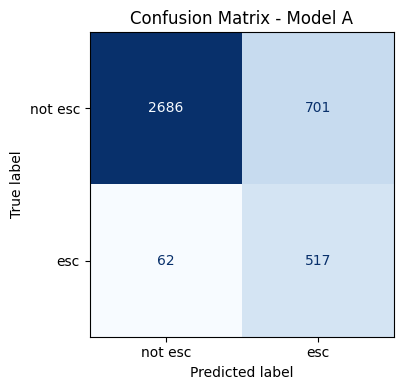

In [66]:
#confusion matrix 
cm = confusion_matrix(y_test, y_pred)
print("=== confusion matrix ===")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["not esc", "esc"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Model A")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

=== ROC-AUC: 0.8918 ===


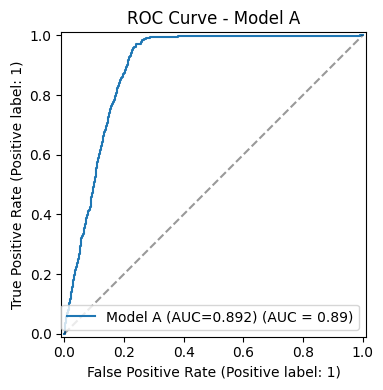

In [67]:
#roc-auc
auc = roc_auc_score(y_test, y_proba)
print(f"=== ROC-AUC: {auc:.4f} ===")

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax, name=f"Model A (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)   # random baseline
ax.set_title("ROC Curve - Model A")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

In [68]:
# cross-validation
# run on the full scaled feature set
print("=== 5-fold stratified CV (AUC) ===")

x_all = pd.concat([x_train_scaled, x_test_scaled])
y_all = pd.concat([y_train, y_test])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_model = XGBClassifier(scale_pos_weight=spw, **parameters)
cv_scores = cross_val_score(cv_model, x_all, y_all, cv=cv, scoring="roc_auc", n_jobs=-1)

print(f"fold AUCs: {np.round(cv_scores, 4)}")
print(f"mean: {cv_scores.mean():.4f}  std: {cv_scores.std():.4f}")

=== 5-fold stratified CV (AUC) ===
fold AUCs: [0.8996 0.8933 0.8956 0.8944 0.9   ]
mean: 0.8966  std: 0.0027


# 12. Results

In [ ]:
import json
import os

tweets = tweets_scored      
threads = df_threads
N_ROOTS = 300
N_MIDDLES = 300
SEED = 42
OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)

label_by_root = dict(zip(threads["thread_root"], threads["escalated"]))

# group tweets into ordered turn lists
grouped = {}
for tid, g in tweets.sort_values("turn_index").groupby("thread_root"):
    grouped[tid] = [
        {"inbound": bool(r.inbound), "text": str(r.text)}
        for r in g.itertuples()
    ]

all_ids = [t for t in grouped if t in label_by_root]

import random
random.seed(SEED)

# Mode 1: roots whose first turn is inbound (a real customer opener)
root_candidates = [
    t for t in all_ids
    if grouped[t] and grouped[t][0]["inbound"]
]
roots_sample = random.sample(root_candidates, min(N_ROOTS, len(root_candidates)))
roots = [
    {
        "thread_root": t,
        "opening_text": grouped[t][0]["text"],
    }
    for t in roots_sample
]

# Mode 2: threads with >= 4 turns following customer -> company -> customer -> ...
middle_candidates = []
for t in all_ids:
    turns = grouped[t]
    if len(turns) < 4:
        continue
    # require the canonical opening pattern: inbound, outbound, inbound
    if turns[0]["inbound"] and (not turns[1]["inbound"]) and turns[2]["inbound"]:
        middle_candidates.append(t)

middles_sample = random.sample(middle_candidates, min(N_MIDDLES, len(middle_candidates)))
middles = [
    {
        "thread_root": t,
        "prompt_turns": grouped[t][:3],          # what the user sees
        "real_continuation": grouped[t][3:],     # the reveal
        "escalated": int(label_by_root[t]),      # the outcome
    }
    for t in middles_sample
]

payload = {"roots": roots, "middles": middles}
with open(os.path.join(OUT, "predictor_threads.json"), "w", encoding='utf-8') as f:
    json.dump(payload, f, ensure_ascii=False, indent=2)

print(f"roots: {len(roots)} (from {len(root_candidates)} candidates)")
print(f"middles: {len(middles)} (from {len(middle_candidates)} candidates)")
print("wrote artifacts/predictor_threads.json")

roots: 300 (from 19828 candidates)
middles: 300 (from 4722 candidates)
wrote artifacts/predictor_threads.json


shap values shape: (3966, 21)


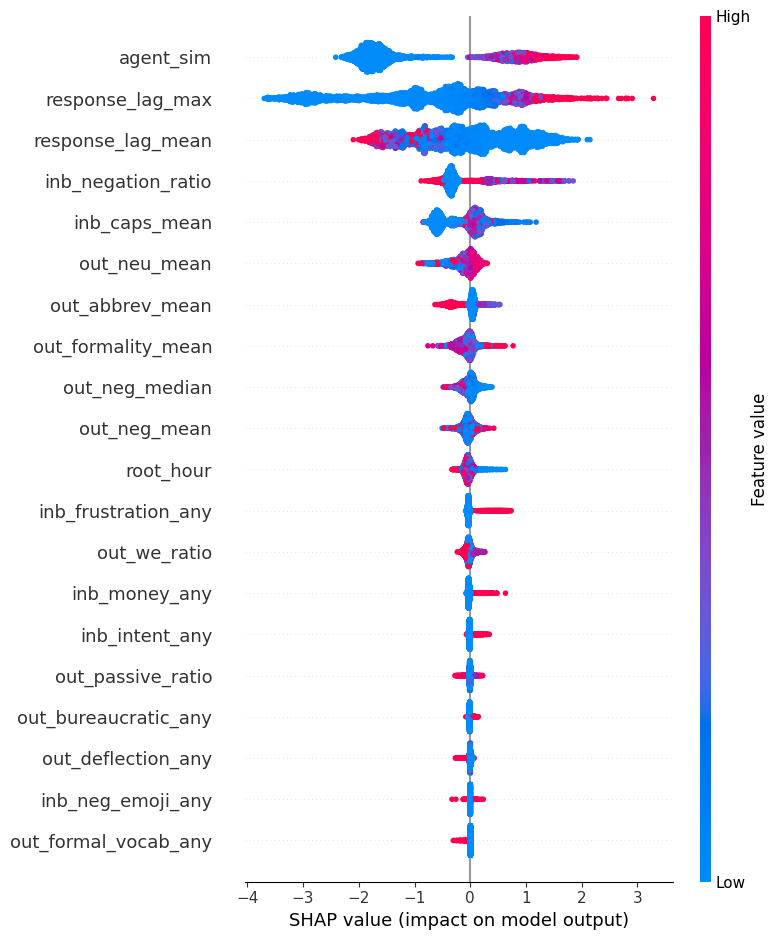

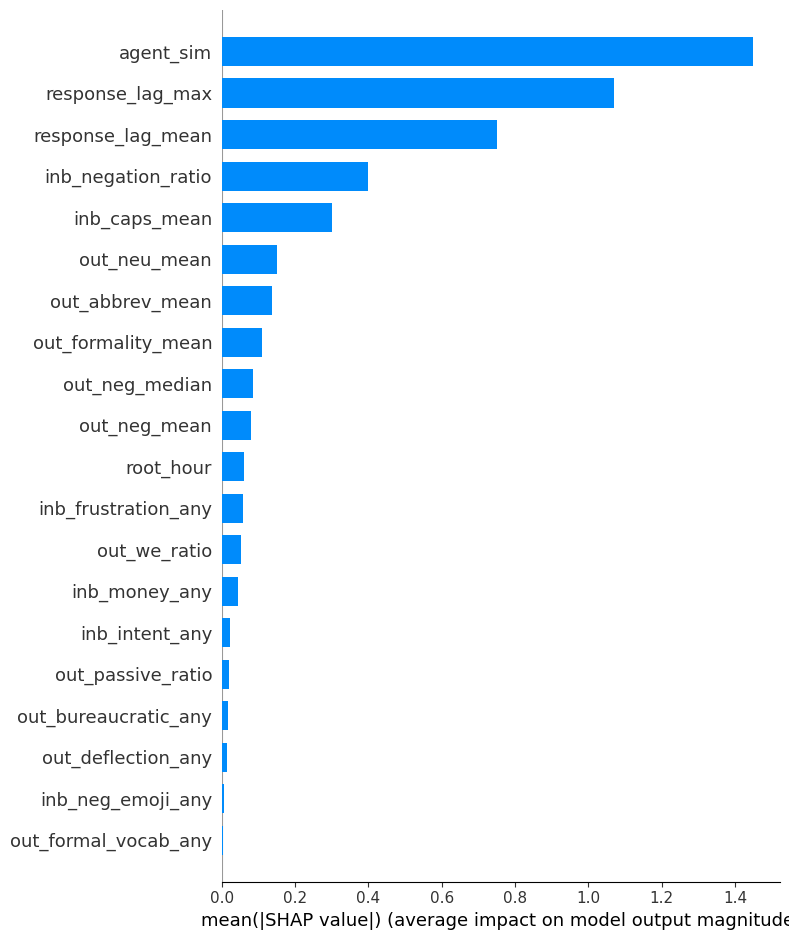


=== SHAP feature ranking ===
             feature  mean_abs_shap
           agent_sim          1.450
    response_lag_max          1.070
   response_lag_mean          0.751
  inb_negation_ratio          0.399
       inb_caps_mean          0.300
        out_neu_mean          0.150
     out_abbrev_mean          0.137
  out_formality_mean          0.111
      out_neg_median          0.084
        out_neg_mean          0.079
           root_hour          0.061
 inb_frustration_any          0.057
        out_we_ratio          0.051
       inb_money_any          0.044
      inb_intent_any          0.022
   out_passive_ratio          0.019
out_bureaucratic_any          0.017
  out_deflection_any          0.014
   inb_neg_emoji_any          0.005
out_formal_vocab_any          0.004
out_contraction_mean          0.000

waterfall for test row 9 (true positive)


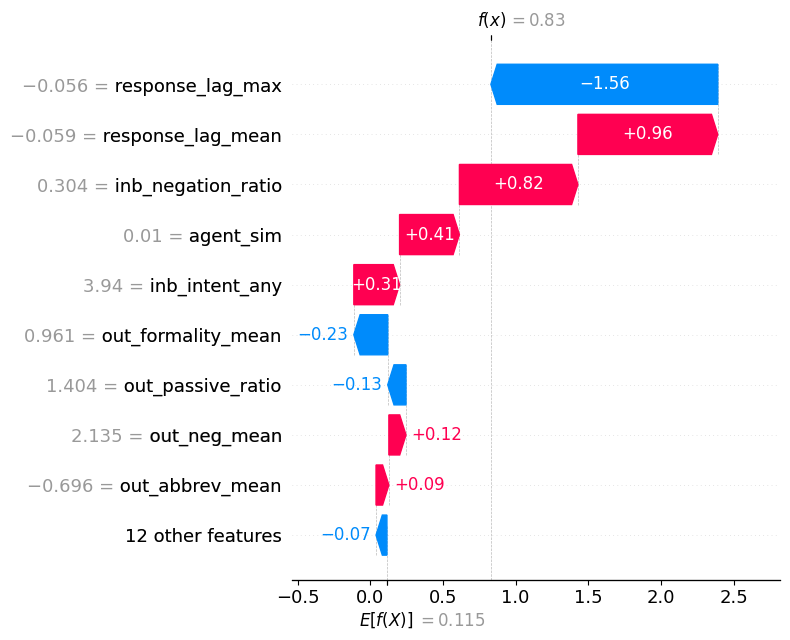

In [74]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# TreeExplainer is the fast exact method for tree models like xgboost
explainer = shap.TreeExplainer(model)

# compute shap values on the test set
# each value = how much that feature pushed a given prediction up/down
shap_values = explainer.shap_values(x_test_scaled)

print("shap values shape:", shap_values.shape)   # (n_test_samples, n_features)


# ── summary plot - global feature importance ─────────────────
# shows which features matter most across ALL predictions
# and the direction (red = high feature value, blue = low)
plt.figure()
shap.summary_plot(shap_values, x_test_scaled, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# ── bar version - mean absolute shap, cleaner ranking ────────
plt.figure()
shap.summary_plot(shap_values, x_test_scaled, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()


# ── ranked importance as a table - for the writeup ───────────
mean_abs = np.abs(shap_values).mean(axis=0)
shap_rank = pd.DataFrame({
    "feature": x_test_scaled.columns,
    "mean_abs_shap": mean_abs,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

print("\n=== SHAP feature ranking ===")
print(shap_rank.to_string(index=False))


# ── waterfall - explain ONE individual prediction ───────────
# pick a true positive (actually escalated, model caught it)
tp_mask = (y_test.values == 1) & (y_pred == 1)
tp_idx  = np.where(tp_mask)[0][0]   # first true positive

print(f"\nwaterfall for test row {tp_idx} (true positive)")
plt.figure()
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[tp_idx],
        base_values=explainer.expected_value,
        data=x_test_scaled.iloc[tp_idx],
        feature_names=list(x_test_scaled.columns),
    ),
    show=False,
)
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

In [95]:
import json
import os

import joblib

OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)

# XGBoost native format is version-robust and reloads cleanly into XGBClassifier.
model_a.save_model(os.path.join(OUT, "model.json"))

# StandardScaler has no native format; joblib is standard for sklearn objects.
joblib.dump(scaler, os.path.join(OUT, "scaler.pkl"))

with open(os.path.join(OUT, "feature_columns.json"), "w") as f:
    json.dump(list(x.columns), f, indent=2)

print(f"wrote {len(x.columns)} feature columns")
print("artifacts/model.json, artifacts/scaler.pkl, artifacts/feature_columns.json")

wrote 21 feature columns
artifacts/model.json, artifacts/scaler.pkl, artifacts/feature_columns.json


In [96]:
OUT = "artifacts"
os.makedirs(OUT, exist_ok=True)
ALPHA = 0.0025  # Bonferroni-adjusted (20 tests)

esc = df_threads[df_threads["escalated"] == 1]
non = df_threads[df_threads["escalated"] == 0]
n_total = len(df_threads)


def rank_biserial(g1, g2, u):
    return 1 - (2 * u) / (len(g1) * len(g2))


def cramers_v(chi2, n, shape):
    return float(np.sqrt(chi2 / (n * min(shape[0] - 1, shape[1] - 1))))


BINARY = [
    ("out_deflection_any",   "Deflection language (agent)"),
    ("out_bureaucratic_any", "Bureaucratic language (agent)"),
    ("inb_frustration_any",  "Frustration terms (customer)"),
    ("inb_intent_any",       "Intent terms (customer)"),
    ("out_formal_vocab_any", "Formal vocabulary (agent)"),
    ("inb_neg_emoji_any",    "Negative emoji (customer)"),
]

CONTINUOUS = [
    ("agent_sim",          "Agent template similarity"),
    ("response_lag_max",   "Max response lag (min)"),
    ("response_lag_mean",  "Mean response lag (min)"),
    ("out_passive_ratio",  "Passive voice ratio (agent)"),
    ("inb_negation_ratio", "Negation ratio (customer)"),
    ("inb_caps_mean",      "Caps ratio (customer)"),
    ("out_we_ratio",       "We-not-I ratio (agent)"),
    ("out_formality_mean", "Formality F-score (agent)"),
]

DIST = ["agent_sim", "response_lag_max", "inb_negation_ratio"]

binary_drivers = []
for f, label in BINARY:
    table = __import__("pandas").crosstab(df_threads["escalated"], df_threads[f])
    chi2, p, _, _ = chi2_contingency(table)
    binary_drivers.append({
        "feature": f, "label": label,
        "esc_rate": round(float(esc[f].mean()), 4),
        "non_rate": round(float(non[f].mean()), 4),
        "cramers_v": round(cramers_v(chi2, n_total, table.shape), 4),
        "p_value": float(p), "significant": bool(p < ALPHA),
    })

continuous_drivers = []
for f, label in CONTINUOUS:
    u, p = mannwhitneyu(esc[f], non[f], alternative="two-sided")
    continuous_drivers.append({
        "feature": f, "label": label,
        "esc_median": round(float(esc[f].median()), 4),
        "non_median": round(float(non[f].median()), 4),
        "rank_biserial": round(float(rank_biserial(esc[f], non[f], u)), 4),
        "p_value": float(p), "significant": bool(p < ALPHA),
    })


def box_stats(s):
    q1, med, q3 = np.percentile(s, [25, 50, 75])
    return {"q1": round(float(q1), 4), "median": round(float(med), 4),
            "q3": round(float(q3), 4), "mean": round(float(s.mean()), 4),
            "lo": round(float(s.min()), 4), "hi": round(float(s.quantile(0.95)), 4)}


distributions = []
for f in DIST:
    label = dict(CONTINUOUS).get(f, f)
    distributions.append({
        "feature": f, "label": label,
        "esc": box_stats(esc[f]), "non": box_stats(non[f]),
    })

# test-set predictions for the ROC + threshold/confusion view
yt = np.asarray(y_test).astype(int).tolist()
yp = [round(float(v), 4) for v in np.asarray(y_proba)]

try:
    shap_panel = [
        {"feature": r.feature, "mean_abs_shap": round(float(r.mean_abs_shap), 5)}
        for r in shap_rank.itertuples()
    ][:15]
except Exception:
    shap_panel = None

from sklearn.metrics import roc_auc_score
auc = float(roc_auc_score(yt, yp))

payload = {
    "source": "real",
    "kpis": {
        "threads": int(n_total),
        "escalated": int((df_threads["escalated"] == 1).sum()),
        "esc_rate": round(float(df_threads["escalated"].mean()), 4),
        "auc": round(auc, 4),
    },
    "binary_drivers": binary_drivers,
    "continuous_drivers": continuous_drivers,
    "distributions": distributions,
    "eval": {"y_true": yt, "y_proba": yp, "auc": round(auc, 4)},
    "shap": shap_panel,
}

with open(os.path.join(OUT, "dashboard_data.json"), "w") as f:
    json.dump(payload, f)

print(f"wrote artifacts/dashboard_data.json  ({len(yt)} test points, "
      f"{len(binary_drivers)} binary + {len(continuous_drivers)} continuous drivers, "
      f"shap={'yes' if shap_panel else 'no'})")

wrote artifacts/dashboard_data.json  (3966 test points, 6 binary + 8 continuous drivers, shap=yes)


In [94]:
import json
d = json.load(open("artifacts/dashboard_data.json"))
print("shap in file:", d["shap"] if d["shap"] is None else f"{len(d['shap'])} rows")
print("shap_rank defined in notebook:", 'shap_rank' in dir())

shap in file: 15 rows
shap_rank defined in notebook: True
